# 02 · Time Drain Analysis & AI Opportunity Sizing
**Question from the client:** *Where does our office team's time actually go, which three drains should we fix first with AI, and what is it worth?*

Approach:
1. **Measure**: annual hours and cost per task (Pareto)
2. **Compare**: what staff *believe* vs what the data shows
3. **Score**: AI-addressable time per task, then pick the top 3 drains
4. **Deep-dive** each drain using operational data (tickets, documents, invoices)
5. **Size**: ROI and payback per initiative, then a phased roadmap

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROC, APP, FIG = Path("../data/processed"), Path("../data/app"), Path("../reports/figures")
APP.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

tl = pd.read_csv(PROC / "time_logs_clean.csv", parse_dates=["work_date"])
tickets = pd.read_csv(PROC / "cs_tickets_clean.csv", parse_dates=["created_at"])
docs = pd.read_csv(PROC / "shipping_documents_clean.csv", parse_dates=["received_date"])
inv = pd.read_csv(PROC / "carrier_invoices_clean.csv")
survey = pd.read_csv(PROC / "employee_survey.csv")
employees = pd.read_csv(PROC / "employees.csv")

# Shared chart style (light surface, one highlight hue, gray context)
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#c9c8c3", "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b5b4ae", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "figure.facecolor": "white", "axes.grid": False})
def yen_m(x): return f"¥{x / 1e6:,.1f}M"

TOTAL_H, TOTAL_COST = tl["hours"].sum(), tl["cost_jpy"].sum()
FTE_HOURS = tl.groupby("employee_id")["hours"].sum().median()  # hours one FTE logs in a year
print(f"Hours logged in 12 months : {TOTAL_H:,.0f} h")
print(f"Loaded staff cost of that : {yen_m(TOTAL_COST)}")
print(f"One FTE logs about        : {FTE_HOURS:,.0f} h / year")

Hours logged in 12 months : 104,555 h
Loaded staff cost of that : ¥355.9M
One FTE logs about        : 1,739 h / year


## 1. Where does the time go?

In [2]:
by_task = (tl.groupby("task_type")
             .agg(hours=("hours", "sum"), cost_jpy=("cost_jpy", "sum"), people=("employee_id", "nunique"),
                  divisions=("division", lambda s: ", ".join(sorted(s.unique()))))
             .sort_values("hours", ascending=False))
by_task["share"] = by_task["hours"] / TOTAL_H
by_task["cum_share"] = by_task["share"].cumsum()
by_task["fte"] = by_task["hours"] / FTE_HOURS
by_task.head(10).round({"hours": 0, "cost_jpy": 0, "share": 3, "cum_share": 3, "fte": 1})

,hours,cost_jpy,people,divisions,share,cum_share,fte
task_type,,,,,,,
Internal meetings,14547.0,59270117.0,60,"Customer Service, Finance, Management, Operati...",0.139,0.139,8.4
Shipping document data entry,11607.0,36278540.0,22,Operations,0.111,0.250,6.7
Shipment status inquiry (WISMO),8379.0,23687811.0,14,Customer Service,0.080,0.330,4.8
Other,7187.0,27059419.0,60,"Customer Service, Finance, Management, Operati...",0.069,0.399,4.1
Carrier invoice reconciliation,6361.0,21512389.0,10,Finance,0.061,0.460,3.7
Warehouse coordination,5274.0,16483528.0,22,Operations,0.050,0.510,3.0
Carrier booking,5023.0,15701411.0,22,Operations,0.048,0.558,2.9
Manual tracking updates,4261.0,13319314.0,22,Operations,0.041,0.599,2.5
Quote preparation,4192.0,12291239.0,8,Sales Admin,0.040,0.639,2.4


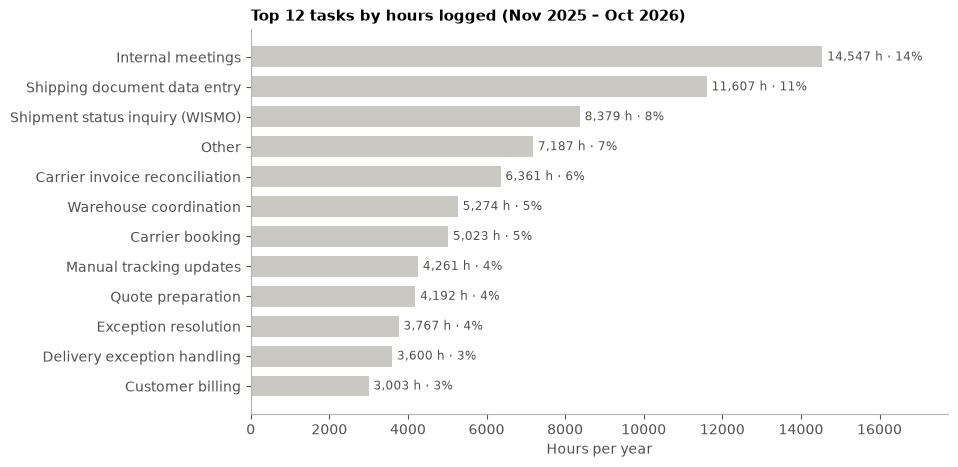

In [3]:
top = by_task.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top["hours"], color=GRAY, height=0.7)
ax.set_xlabel("Hours per year")
ax.set_title("Top 12 tasks by hours logged (Nov 2025 – Oct 2026)", loc="left")
for y, (h, s) in enumerate(zip(top["hours"], top["share"])):
    ax.text(h + 120, y, f"{h:,.0f} h · {s:.0%}", va="center", fontsize=8.5, color=MUTED)
ax.set_xlim(0, top["hours"].max() * 1.22)
fig.savefig(FIG / "01_hours_by_task.png", dpi=160, bbox_inches="tight")

**Reading:** internal meetings are the single largest block (~14% of all hours), followed by shipping document data entry, shipment-status inquiries (WISMO) and carrier invoice reconciliation. Raw hours alone don't tell us where *AI* helps, so the next steps add two lenses: perception and addressability.

In [4]:
div_task = tl.pivot_table(index="division", columns="task_type", values="hours", aggfunc="sum", fill_value=0)
div_share = (div_task.T / div_task.sum(axis=1)).T
for d in div_share.index:
    t3 = div_share.loc[d].sort_values(ascending=False).head(3)
    print(f"{d:17s} " + " | ".join(f"{k} {v:.0%}" for k, v in t3.items()))

Customer Service  Shipment status inquiry (WISMO) 34% | Delivery exception handling 15% | Booking change request 12%
Finance           Carrier invoice reconciliation 36% | Customer billing 17% | Accounts payable processing 14%
Management        Internal meetings 42% | Management reporting 23% | Approvals 20%
Operations        Shipping document data entry 30% | Warehouse coordination 14% | Carrier booking 13%
Sales Admin       Quote preparation 30% | Rate lookup 18% | CRM updates 15%


## 2. Perception vs data
Before looking at the logs, staff answered a short survey: *"What are your three biggest time drains?"* We map each answer to the matching task group and compare the share of votes with the share of hours.

In [5]:
group_map = {
    "Internal meetings": ["Internal meetings"],
    "Shipment status inquiries (WISMO)": ["Shipment status inquiry (WISMO)"],
    "Shipping document data entry": ["Shipping document data entry"],
    "Carrier invoice reconciliation": ["Carrier invoice reconciliation"],
    "Reporting in Excel": [t for t in by_task.index if "reporting" in t.lower()],
    "Exception handling": ["Delivery exception handling", "Exception resolution"],
    "Quote preparation": ["Quote preparation"],
}
votes = (survey.melt(value_vars=["biggest_time_drain_1", "biggest_time_drain_2", "biggest_time_drain_3"],
                     var_name="rank", value_name="group"))
votes["weight"] = votes["rank"].map({"biggest_time_drain_1": 3, "biggest_time_drain_2": 2, "biggest_time_drain_3": 1})
perc = votes.groupby("group")["weight"].sum()
hours_grp = pd.Series({g: by_task.loc[by_task.index.intersection(ts), "hours"].sum() for g, ts in group_map.items()})
perception = pd.DataFrame({"perceived_share": perc / perc.sum(), "actual_share": hours_grp / hours_grp.sum()}).fillna(0)
perception["gap_pts"] = (perception["actual_share"] - perception["perceived_share"]) * 100
perception = perception.sort_values("actual_share", ascending=False)
perception.round(3)

,perceived_share,actual_share,gap_pts
Internal meetings,0.298,0.235,-6.299
Shipping document data entry,0.110,0.187,7.708
Reporting in Excel,0.196,0.154,-4.242
Shipment status inquiries (WISMO),0.098,0.135,3.693
Exception handling,0.164,0.119,-4.487
Carrier invoice reconciliation,0.068,0.103,3.414
Quote preparation,0.065,0.068,0.213


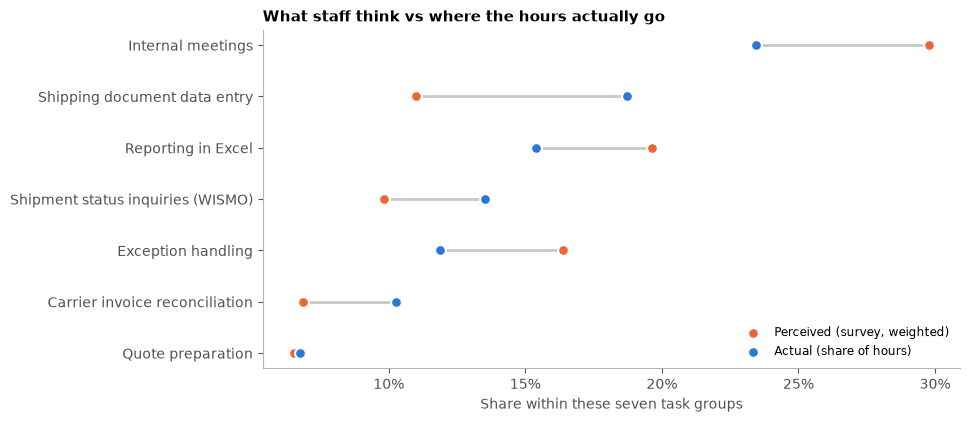

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.4))
p = perception.iloc[::-1]
y = np.arange(len(p))
ax.hlines(y, p[["perceived_share", "actual_share"]].min(axis=1), p[["perceived_share", "actual_share"]].max(axis=1),
          color=GRAY, lw=2)
ax.scatter(p["perceived_share"], y, s=60, color=ORANGE, zorder=3, label="Perceived (survey, weighted)", edgecolor="white", lw=1.5)
ax.scatter(p["actual_share"], y, s=60, color=BLUE, zorder=3, label="Actual (share of hours)", edgecolor="white", lw=1.5)
ax.set_yticks(y, p.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("What staff think vs where the hours actually go", loc="left")
ax.set_xlabel("Share within these seven task groups")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
fig.savefig(FIG / "02_perception_vs_actual.png", dpi=160, bbox_inches="tight")

**Reading:** staff over-weight meetings and Excel reporting (visible, frustrating work) and under-weight high-volume repetitive work that is spread thinly through the day: document keying, status inquiries and invoice checking. This gap is exactly why the audit starts from logged time rather than opinion.

## 3. Which drains can AI actually remove?
Hours are only half of the story. For each task we estimate the **share of time AI/automation can realistically remove** within 12 months, based on how repetitive, rule-based and digital the work is. These are analyst assumptions, documented here so the client can challenge them.

In [7]:
addressable = {
    "Shipping document data entry": (0.70, "Intelligent document processing (OCR + LLM extraction) with human validation"),
    "Shipment status inquiry (WISMO)": (0.60, "Proactive tracking notifications + LLM auto-reply grounded in TMS data"),
    "Carrier invoice reconciliation": (0.65, "Automated rate-card matching with anomaly flags; humans handle exceptions only"),
    "Manual tracking updates": (0.60, "Carrier API / EDI integration (automation, not AI)"),
    "Rate lookup": (0.50, "Rate search assistant over contract rate sheets"),
    "Accounts payable processing": (0.45, "Invoice capture + 3-way match"),
    "CRM updates": (0.40, "Auto-logging of emails/calls into CRM"),
    "Quote preparation": (0.35, "Quote drafting from templates + rate assistant"),
    "Customer billing": (0.30, "Billing rules automation"),
    "Booking change request": (0.30, "Self-service change form + auto-classification"),
    "Carrier booking": (0.30, "Booking via carrier APIs"),
    "Damage / claim handling": (0.25, "Claim intake form + document summarisation"),
    "Month-end close": (0.20, "Close checklist automation"),
    "Delivery exception handling": (0.20, "Exception triage and suggested next action"),
    "Approvals": (0.15, "Workflow routing"),
    "Exception resolution": (0.15, "Exception triage and suggested next action"),
    "Internal meetings": (0.10, "AI meeting notes and action items (limited impact)"),
    "Warehouse coordination": (0.10, "Shared status board"),
    "Training / admin": (0.10, "Knowledge assistant"),
    "Other": (0.05, "-"),
}
for t in [t for t in by_task.index if "reporting" in t.lower()]:
    addressable[t] = (0.40, "Automated BI dashboards replace copy-paste Excel reports")

score = by_task[["hours", "cost_jpy", "share", "people"]].copy()
score["ai_addressable_pct"] = score.index.map(lambda t: addressable[t][0])
score["ai_lever"] = score.index.map(lambda t: addressable[t][1])
score["addressable_hours"] = score["hours"] * score["ai_addressable_pct"]
score["addressable_cost_jpy"] = score["cost_jpy"] * score["ai_addressable_pct"]
score = score.sort_values("addressable_cost_jpy", ascending=False)
score["rank"] = range(1, len(score) + 1)
score[["hours", "ai_addressable_pct", "addressable_hours", "addressable_cost_jpy", "ai_lever"]].head(8).round({"hours": 0, "ai_addressable_pct": 2, "addressable_hours": 0, "addressable_cost_jpy": 0})

,hours,ai_addressable_pct,addressable_hours,addressable_cost_jpy,ai_lever
task_type,,,,,
Shipping document data entry,11607.0,0.70,8125.0,25394978.0,Intelligent document processing (OCR + LLM ext...
Shipment status inquiry (WISMO),8379.0,0.60,5027.0,14212686.0,Proactive tracking notifications + LLM auto-re...
Carrier invoice reconciliation,6361.0,0.65,4135.0,13983053.0,Automated rate-card matching with anomaly flag...
Manual tracking updates,4261.0,0.60,2557.0,7991588.0,"Carrier API / EDI integration (automation, not..."
Management reporting,2411.0,0.40,964.0,6191086.0,Automated BI dashboards replace copy-paste Exc...
Internal meetings,14547.0,0.10,1455.0,5927012.0,AI meeting notes and action items (limited imp...
Carrier booking,5023.0,0.30,1507.0,4710423.0,Booking via carrier APIs
Quote preparation,4192.0,0.35,1467.0,4301933.0,Quote drafting from templates + rate assistant


TOP 3: ['Shipping document data entry', 'Shipment status inquiry (WISMO)', 'Carrier invoice reconciliation']


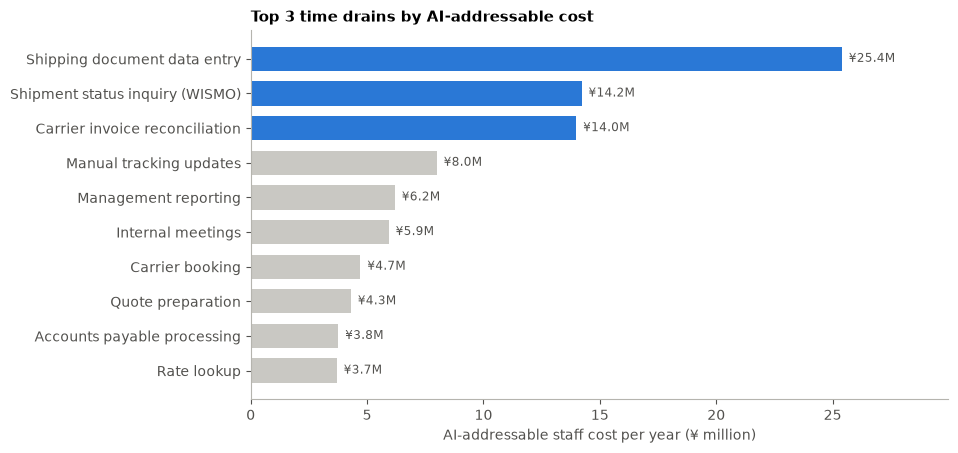

In [8]:
TOP3 = score.index[:3].tolist()
s = score.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
colors = [BLUE if t in TOP3 else GRAY for t in s.index]
ax.barh(s.index, s["addressable_cost_jpy"] / 1e6, color=colors, height=0.7)
for yv, v in enumerate(s["addressable_cost_jpy"] / 1e6):
    ax.text(v + 0.3, yv, f"¥{v:,.1f}M", va="center", fontsize=8.5, color=MUTED)
ax.set_xlabel("AI-addressable staff cost per year (¥ million)")
ax.set_title("Top 3 time drains by AI-addressable cost", loc="left")
ax.set_xlim(0, s["addressable_cost_jpy"].max() / 1e6 * 1.18)
fig.savefig(FIG / "03_ai_addressable_cost.png", dpi=160, bbox_inches="tight")
print("TOP 3:", TOP3)

**Result.** Meetings fall from #1 by hours to a minor opportunity, because AI can only trim them. The top 3 AI opportunities are:

1. **Shipping document data entry** (Operations)
2. **Shipment status inquiries / WISMO** (Customer Service)
3. **Carrier invoice reconciliation** (Finance)

Together they consume about a quarter of all logged hours, nearly twice the time spent in meetings. `Manual tracking updates` ranks 4th and shares a root cause with WISMO (no automated tracking feed), so it is folded into the WISMO initiative.

In [9]:
t3 = score.loc[TOP3]
print(f"Top 3 share of all hours  : {t3['hours'].sum() / TOTAL_H:.1%}")
print(f"Meetings share of hours   : {by_task.loc['Internal meetings', 'share']:.1%}")
print(f"Top 3 hours / FTE         : {t3['hours'].sum():,.0f} h  ≈ {t3['hours'].sum() / FTE_HOURS:.1f} FTE")

Top 3 share of all hours  : 25.2%
Meetings share of hours   : 13.9%
Top 3 hours / FTE         : 26,347 h  ≈ 15.2 FTE


## 4. Deep dives
### 4a. Shipping document data entry

In [10]:
d = (docs.groupby("doc_type")
         .agg(docs=("doc_id", "count"), avg_fields=("fields_keyed", "mean"), avg_entry_min=("entry_min", "mean"),
              error_rate=("field_errors", lambda x: (x > 0).mean()), rework_h=("rework_min", lambda x: x.sum() / 60))
         .sort_values("docs", ascending=False))
d.round(2)

,docs,avg_fields,avg_entry_min,error_rate,rework_h
doc_type,,,,,
Delivery note,15593,15.01,6.49,0.17,496.21
Packing list,11147,22.98,9.96,0.24,528.89
Commercial invoice,6146,29.00,12.53,0.29,369.82
Bill of lading,4942,35.02,15.19,0.35,370.18
Customs declaration,3172,40.93,17.69,0.39,277.16


In [11]:
fmt = docs.groupby("source_format").agg(docs=("doc_id", "count"), error_rate=("field_errors", lambda x: (x > 0).mean()))
fmt["share"] = fmt["docs"] / fmt["docs"].sum()
print(fmt.round(3))
print(f"\nDocuments keyed per year : {len(docs):,}")
print(f"Docs with >=1 keying error: {(docs['field_errors'] > 0).mean():.1%}")
print(f"Rework hours from errors : {docs['rework_min'].sum() / 60:,.0f} h")

                docs  error_rate  share
source_format                          
Excel           6113       0.241  0.149
Fax             4134       0.254  0.101
PDF (email)    19819       0.245  0.483
Scanned paper  10934       0.240  0.267

Documents keyed per year : 41,000
Docs with >=1 keying error: 24.4%
Rework hours from errors : 2,042 h


**Finding:** ~41k documents a year are re-typed by hand, about one in four contains at least one keying error, and errors create their own rework. About 75% arrive as PDF or scans, so they are good candidates for intelligent document processing. Excel files can be imported directly without AI.

### 4b. Shipment status inquiries (WISMO)

In [12]:
cat_share = tickets["category"].value_counts(normalize=True)
tick = (tickets.dropna(subset=["category"]).groupby("category")
               .agg(tickets=("ticket_id", "count"), avg_handle_min=("handling_min", "mean"),
                    reopen_rate=("reopened", "mean"), median_first_response_min=("first_response_min", "median"))
               .sort_values("tickets", ascending=False))
tick["share"] = tick["tickets"] / tick["tickets"].sum()
tick.round(2)

,tickets,avg_handle_min,reopen_rate,median_first_response_min,share
category,,,,,
WISMO,11391,9.75,0.22,94.0,0.46
Delivery exception,3772,25.91,0.08,95.0,0.15
Booking change,3461,14.06,0.08,94.0,0.14
Other,2788,10.68,0.08,94.0,0.11
Billing question,1996,21.83,0.08,94.0,0.08
Damage / claim,1546,40.76,0.07,96.0,0.06


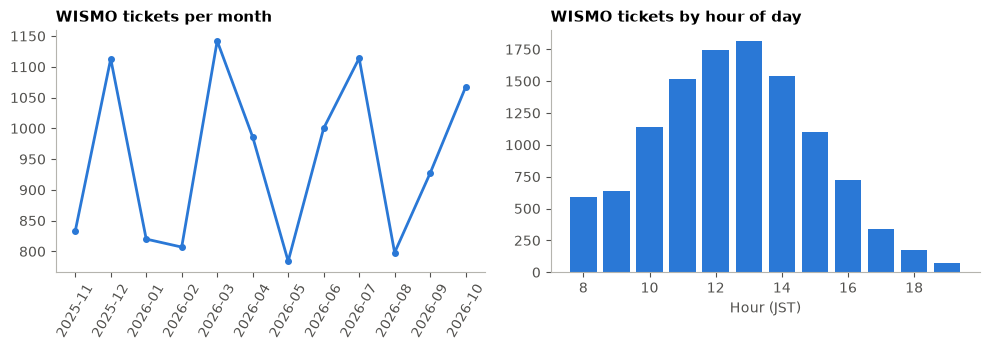

In [13]:
tickets["hour"] = tickets["created_at"].dt.hour
w = tickets[tickets["category"] == "WISMO"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
m = tickets.dropna(subset=["category"]).assign(is_wismo=lambda x: x["category"] == "WISMO") \
          .groupby("month")["is_wismo"].agg(["sum", "count"])
axes[0].plot(m.index, m["sum"], color=BLUE, lw=2, marker="o", ms=4)
axes[0].set_title("WISMO tickets per month", loc="left")
axes[0].tick_params(axis="x", rotation=60)
hourly = w.groupby("hour")["ticket_id"].count()
axes[1].bar(hourly.index, hourly.values, color=BLUE, width=0.8)
axes[1].set_title("WISMO tickets by hour of day", loc="left"); axes[1].set_xlabel("Hour (JST)")
fig.tight_layout()
fig.savefig(FIG / "04_wismo_patterns.png", dpi=160, bbox_inches="tight")

**Finding:** WISMO ("where is my shipment?") is ~46% of all labelled tickets. Each is quick (~9 min), but the volume is relentless, peaks in December and March, and over one in five is *reopened* because the customer chases again before getting an answer (median first response ≈ 1.5 h). The information already exists in the TMS; customers just can't see it.

### 4c. Carrier invoice reconciliation

In [14]:
car = (inv.groupby("carrier")
          .agg(lines=("line_id", "count"), mismatch_rate=("is_mismatch", "mean"),
               overbilled_jpy=("overbilled_jpy", "sum"),
               unrecovered_jpy=("overbilled_jpy", lambda x: x[~inv.loc[x.index, "recovered"]].sum()))
          .sort_values("overbilled_jpy", ascending=False))
car.round(3)

,lines,mismatch_rate,overbilled_jpy,unrecovered_jpy
carrier,,,,
Carrier A (national parcel),11671,0.134,6922000.0,2516150.0
Carrier B (LTL),7985,0.137,5074300.0,2217370.0
Carrier C (FTL),5421,0.141,3313820.0,1178120.0
Carrier D (regional),5502,0.138,3082200.0,1180550.0
Carrier E (cold chain),3421,0.145,2126130.0,757250.0


In [15]:
reason = (inv[inv["is_mismatch"]].groupby("mismatch_reason")
            .agg(lines=("line_id", "count"), overbilled_jpy=("overbilled_jpy", "sum"))
            .sort_values("overbilled_jpy", ascending=False))
OVERBILLED = inv["overbilled_jpy"].sum()
UNRECOVERED = inv.loc[inv["is_mismatch"] & ~inv["recovered"], "overbilled_jpy"].sum()
print(reason)
print(f"\nInvoice lines checked by hand  : {len(inv):,}")
print(f"Lines with overbilling         : {inv['is_mismatch'].mean():.1%}")
print(f"Overbilled in 12 months        : {yen_m(OVERBILLED)}")
print(f"...of which never recovered    : {yen_m(UNRECOVERED)}  ({UNRECOVERED / OVERBILLED:.0%})")

                        lines  overbilled_jpy
mismatch_reason                              
Fuel surcharge           1447       6253080.0
Wrong weight tier        1128       5021220.0
Accessorial not agreed    862       3699950.0
Rate not updated          688       3123710.0
Duplicate charge          555       2420490.0

Invoice lines checked by hand  : 34,000
Lines with overbilling         : 13.8%
Overbilled in 12 months        : ¥20.5M
...of which never recovered    : ¥7.8M  (38%)


**Finding:** every carrier invoice line is checked by hand, yet only ~14% contain a discrepancy. Of the overbilling found, almost 40% is never recovered because disputes are slow and manual. Automated matching flips the work: machines check 100% of lines, people only handle the exceptions, and recovery improves.

## 5. ROI and payback
Value = staff hours freed × average loaded hourly cost of the people doing that task. For invoices we add improved overbilling recovery. Costs are market-typical estimates for a company of this size (SaaS + integration), stated in yen and meant to be replaced with vendor quotes.

In [16]:
avg_rate = (tl.groupby("task_type")["cost_jpy"].sum() / tl.groupby("task_type")["hours"].sum())
initiatives = pd.DataFrame([
    dict(initiative="Intelligent document processing", task="Shipping document data entry",
         automation_pct=0.70, one_off_jpy=6_000_000, annual_jpy=4_200_000, extra_benefit_jpy=0),
    dict(initiative="Proactive tracking + LLM reply assistant", task="Shipment status inquiry (WISMO)",
         automation_pct=0.60, one_off_jpy=4_500_000, annual_jpy=2_400_000, extra_benefit_jpy=0),
    dict(initiative="Automated invoice matching", task="Carrier invoice reconciliation",
         automation_pct=0.65, one_off_jpy=3_500_000, annual_jpy=1_800_000,
         extra_benefit_jpy=round(OVERBILLED * (0.90 - (1 - UNRECOVERED / OVERBILLED)), -4)),
])
initiatives["baseline_hours"] = initiatives["task"].map(by_task["hours"])
initiatives["avg_hourly_cost_jpy"] = initiatives["task"].map(avg_rate).round(0)
initiatives["hours_freed"] = initiatives["baseline_hours"] * initiatives["automation_pct"]
initiatives["fte_freed"] = initiatives["hours_freed"] / FTE_HOURS
initiatives["time_value_jpy"] = initiatives["hours_freed"] * initiatives["avg_hourly_cost_jpy"]
initiatives["gross_benefit_jpy"] = initiatives["time_value_jpy"] + initiatives["extra_benefit_jpy"]
initiatives["net_annual_jpy"] = initiatives["gross_benefit_jpy"] - initiatives["annual_jpy"]
initiatives["payback_months"] = initiatives["one_off_jpy"] / (initiatives["net_annual_jpy"] / 12)
initiatives["roi_year1"] = (initiatives["net_annual_jpy"] - initiatives["one_off_jpy"]) / (initiatives["one_off_jpy"] + initiatives["annual_jpy"])
cols = ["initiative", "baseline_hours", "hours_freed", "fte_freed", "time_value_jpy", "extra_benefit_jpy",
        "one_off_jpy", "annual_jpy", "net_annual_jpy", "payback_months", "roi_year1"]
initiatives[cols].round(2)

,initiative,baseline_hours,hours_freed,fte_freed,time_value_jpy,extra_benefit_jpy,one_off_jpy,annual_jpy,net_annual_jpy,payback_months,roi_year1
0,Intelligent document processing,11606.92,8124.85,4.67,25398273.28,0.0,6000000,4200000,21198273.28,3.40,1.49
1,Proactive tracking + LLM reply assistant,8379.02,5027.41,2.89,14212496.55,0.0,4500000,2400000,11812496.55,4.57,1.06
2,Automated invoice matching,6361.08,4134.70,2.38,13983562.16,5800000.0,3500000,1800000,17983562.16,2.34,2.73


In [17]:
tot = initiatives[["hours_freed", "fte_freed", "gross_benefit_jpy", "one_off_jpy", "annual_jpy", "net_annual_jpy"]].sum()
print(f"Hours freed per year     : {tot['hours_freed']:,.0f} h (≈ {tot['fte_freed']:.1f} FTE)")
print(f"Gross annual benefit     : {yen_m(tot['gross_benefit_jpy'])}")
print(f"One-off investment       : {yen_m(tot['one_off_jpy'])}")
print(f"Running cost per year    : {yen_m(tot['annual_jpy'])}")
print(f"Net annual benefit       : {yen_m(tot['net_annual_jpy'])}")
print(f"Blended payback          : {tot['one_off_jpy'] / (tot['net_annual_jpy'] / 12):.1f} months")

Hours freed per year     : 17,287 h (≈ 9.9 FTE)
Gross annual benefit     : ¥59.4M
One-off investment       : ¥14.0M
Running cost per year    : ¥8.4M
Net annual benefit       : ¥51.0M
Blended payback          : 3.3 months


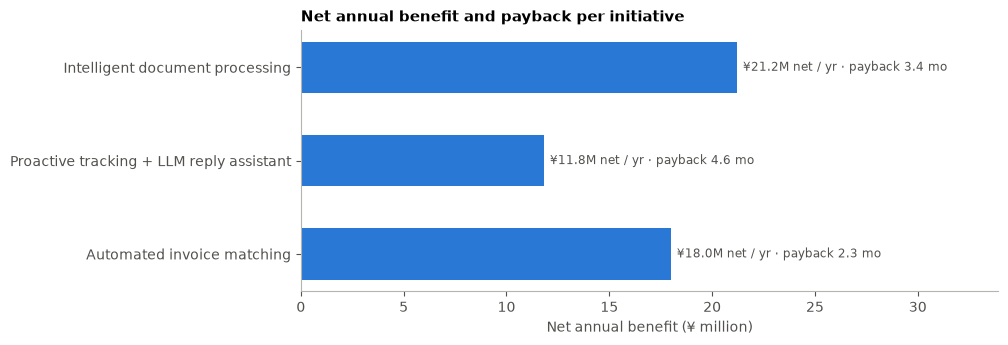

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ii = initiatives.iloc[::-1]
ax.barh(ii["initiative"], ii["net_annual_jpy"] / 1e6, color=BLUE, height=0.55)
for yv, (v, pb) in enumerate(zip(ii["net_annual_jpy"] / 1e6, ii["payback_months"])):
    ax.text(v + 0.3, yv, f"¥{v:,.1f}M net / yr · payback {pb:.1f} mo", va="center", fontsize=8.5, color=MUTED)
ax.set_xlim(0, ii["net_annual_jpy"].max() / 1e6 * 1.6)
ax.set_xlabel("Net annual benefit (¥ million)")
ax.set_title("Net annual benefit and payback per initiative", loc="left")
fig.savefig(FIG / "05_roi.png", dpi=160, bbox_inches="tight")

### Sensitivity: what if automation delivers only half?
Assumptions are the weakest part of any ROI, so we stress-test them.

In [19]:
rows = []
for f in [0.5, 0.75, 1.0]:
    hf = initiatives["baseline_hours"] * initiatives["automation_pct"] * f
    net = hf * initiatives["avg_hourly_cost_jpy"] + initiatives["extra_benefit_jpy"] * f - initiatives["annual_jpy"]
    rows.append({"scenario": f"{int(f * 100)}% of planned automation",
                 "net_annual_jpy": net.sum(), "payback_months": initiatives["one_off_jpy"].sum() / (net.sum() / 12)})
sens = pd.DataFrame(rows)
sens.round(1)

,scenario,net_annual_jpy,payback_months
0,50% of planned automation,21297166.0,7.9
1,75% of planned automation,36145749.0,4.6
2,100% of planned automation,50994332.0,3.3


Even at half the planned automation, the programme still pays back in under 8 months. Note that freed hours are **capacity**, not automatic cash savings. The value is realised by absorbing volume growth without new hires, cutting overtime in peak months (December, March), and moving staff to higher-value work.

## 6. Export tables for the dashboard

In [20]:
score.reset_index().to_csv(APP / "task_scores.csv", index=False)
tl.groupby(["month", "task_type"])["hours"].sum().reset_index().to_csv(APP / "monthly_task_hours.csv", index=False)
tl.groupby(["division", "task_type"])[["hours", "cost_jpy"]].sum().reset_index().to_csv(APP / "division_task.csv", index=False)
perception.reset_index(names="group").to_csv(APP / "perception.csv", index=False)
initiatives.to_csv(APP / "initiatives.csv", index=False)
d.reset_index().to_csv(APP / "docs_by_type.csv", index=False)
fmt.reset_index().to_csv(APP / "docs_by_format.csv", index=False)
tick.reset_index().to_csv(APP / "tickets_by_category.csv", index=False)
tickets.groupby(["month", "category"])["ticket_id"].count().reset_index(name="tickets").to_csv(APP / "tickets_monthly.csv", index=False)
car.reset_index().to_csv(APP / "invoices_by_carrier.csv", index=False)
reason.reset_index().to_csv(APP / "invoices_by_reason.csv", index=False)
pd.Series({"total_hours": TOTAL_H, "total_cost_jpy": TOTAL_COST, "fte_hours": FTE_HOURS, "staff": len(employees),
           "overbilled_jpy": OVERBILLED, "unrecovered_jpy": UNRECOVERED, "docs": len(docs),
           "tickets": len(tickets), "invoice_lines": len(inv)}).to_csv(APP / "kpis.csv", header=["value"])
tickets[["message_text", "category"]].to_csv(APP / "tickets_text.csv", index=False)
print(sorted(p.name for p in APP.glob("*.csv")))

['division_task.csv', 'docs_by_format.csv', 'docs_by_type.csv', 'initiatives.csv', 'invoices_by_carrier.csv', 'invoices_by_reason.csv', 'kpis.csv', 'monthly_task_hours.csv', 'perception.csv', 'task_scores.csv', 'tickets_by_category.csv', 'tickets_monthly.csv', 'tickets_text.csv']
